# Лекция 10: Компьютерное зрение

## Flows

**Преподаватель:** Весельев Александр

**Аудитория:** МФТИ

---

## Содержание

1. Normalizing Flow
2. Continuous Normalizing Flow
3. Flow Matching & Rectified Flow

---

## 1. Normalizing Flow

### 1. Постановка задачи. CoV

**Матрица Якоби**

Пусть задано отображение между многомерными пространствами:
$$
f: \mathbb{R}^n \to \mathbb{R}^m
$$

Матрица Якоби функции $f$ определяется как матрица частных производных:
$$
J_f(x) =
\begin{pmatrix}
\frac{\partial f_1}{\partial x_1} & \cdots & \frac{\partial f_1}{\partial x_n} \\
\vdots & \ddots & \vdots \\
\frac{\partial f_m}{\partial x_1} & \cdots & \frac{\partial f_m}{\partial x_n}
\end{pmatrix}
$$

Когда матрица Якоби квадратная (n=m) можно рассматривать её определитель:
$$
\det J_f(x)
$$

геометрический смысл:

* он показывает, **во сколько раз локально изменяется объём** при преобразовании $f$
* знак определяет ориентацию
* абсолютное значение коэффициент масштабирования


**Теорема замены переменных: Change of Variables Theorem (CoV)**

* $x \sim p_X(x)$
* $z = f(x)$, где $f$ биективное и дифференцируемое отображение

Тогда плотность распределения $z$ выражается как:
$$
p_Z(z) = p_X(f^{-1}(z)) \cdot \left| \det J_{f^{-1}}(z) \right|
$$

Эквивалентная форма:
$$
p_X(x) = p_Z(f(x)) \cdot \left| \det J_f(x) \right|
$$

Дополнительно:

$$\left| \det J_{f^{-1}} \right| = \left| \det {J_{f}}^{-1} \right| = \frac{1}{\left| \det {J_{f}} \right|}$$

<img src="./assets/jac.png" width="300">

**MLE Problem**

$$
p_X(x | \theta) = p_Z(f_\theta(x)) \cdot \left| \det J_{f_{\theta}}(x) \right|
$$

$$
log p(x | \theta) = \log p_Z(f_\theta(x)) +  log \left| \det J_{f_{\theta}}(x) \right| \rightarrow \max_{\theta}

$$

<img src="./assets/nf.png" width="1000">

Теперь, если мы можем разложить функцию преобразования на композицию "хороших" функций, то есть

$z = f(x) = f_K \circ\dots\circ f_1(x)$

Обозначим $h_0=x$, $h_k=f_k(h_{k-1})$, $h_K=z$. Якобианы вычисляются в промежуточных точках:

$$
p_X(x) = p_Z(h_K) \prod_{k=1}^K |\det J_{f_k}(h_{k-1})|
$$

<img src="./assets/nf-comp.png" width="900">

Собрав все вместе, получаем формулу для вычисления MLE:

$$
log p(x | \theta) = \log p_Z(f_\theta(x)) + \sum_{k=1}^K{log|\det J_{f_{\theta_k}}(h_{k-1})|}
$$

---

### 2. Примеры NF

#### Linear Normalizing Flow 

Рассмотрим самый простой класс нормализующих потоков — **линейные normalizing flows**

Аффинное преобразование из шума в данные:

$$
x = g(z) = Az + b
$$

где:

* $A \in \mathbb{R}^{n \times n}$ невырожденная матрица
* $b \in \mathbb{R}^n$ вектор сдвига

обычное аффинное преобразование


Так как $A$ невырождена, существует обратная матрица:

$$
z = A^{-1}(x - b)
$$

Для линейного преобразования якобиан имеет простой вид:

$$
J_g(z) = A
$$

Он не зависит от $z$ поэтому:

$$
\det J_g(z) = \det A
$$

Плотность распределения

$$
\log p_X(x) = \log p_Z(A^{-1}(x - b)) - \log |\det A|
$$

**Проблемы**

- Вычисление детерминанта
   * Требуется считать $\det A$
   * В общем случае: $O(n^3)$

- Обращение матрицы
   * Нужно для перехода $x \to z$
   * Стоимость: $O(n^3)$

- Плохая масштабируемость

Эти проблемы можно стараться решать, упрощая матрицы (диагональные, треугольные, ортогональные, LU, QR разложения)



In [ ]:
import math
import numpy as np
import torch
from torch import nn

torch.manual_seed(7)
linear_rng = torch.Generator().manual_seed(17)
true_A = torch.tensor([[1.8, 0.0], [1.1, 0.55]])
true_b = torch.tensor([2.0, -1.0])
linear_data = torch.randn(2000, 2, generator=linear_rng) @ true_A.T + true_b
linear_noise = torch.randn(2000, 2, generator=linear_rng)

class LinearFlow(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_diag = nn.Parameter(torch.zeros(2))
        self.lower = nn.Parameter(torch.zeros(()))
        self.shift = nn.Parameter(torch.zeros(2))

    def matrix(self):
        zero = self.lower * 0
        return torch.stack([
            torch.stack([self.log_diag[0].exp(), zero]),
            torch.stack([self.lower, self.log_diag[1].exp()]),
        ])

    def log_prob(self, x):
        # решаем A z = x - b, не вычисляя обратную матрицу A явно.
        z = torch.linalg.solve_triangular(
            self.matrix(), (x - self.shift).T, upper=False
        ).T

        log_pz = -0.5 * (z.square() + math.log(2 * math.pi)).sum(dim=1)

        # У треугольной A determinant равен произведению диагональных элементов.
        log_det = self.log_diag.sum()

        return log_pz - log_det

    def sample(self, z):
        return z @ self.matrix().T + self.shift

linear_flow = LinearFlow()
optimizer = torch.optim.Adam(linear_flow.parameters(), lr=0.03)
linear_losses = []
with torch.no_grad():
    linear_before = linear_flow.sample(linear_noise).numpy().copy()

for step in range(600):
    loss = -linear_flow.log_prob(linear_data).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    linear_losses.append(loss.item())

with torch.no_grad():
    linear_after = linear_flow.sample(linear_noise).numpy()
    linear_encoded = torch.linalg.solve_triangular(
        linear_flow.matrix(), (linear_data - linear_flow.shift).T, upper=False
    ).T.numpy()
print(f"NLL: {linear_losses[0]:.3f} → {linear_losses[-1]:.3f}")
print("Learned shift:", linear_flow.shift.detach().numpy())
print("Learned A:\n", linear_flow.matrix().detach().numpy())

NLL: 6.742 → 2.818
Learned shift: [ 2.0266247  -0.99350345]
Learned A:
 [[1.8047415  0.        ]
 [1.0777249  0.54337746]]


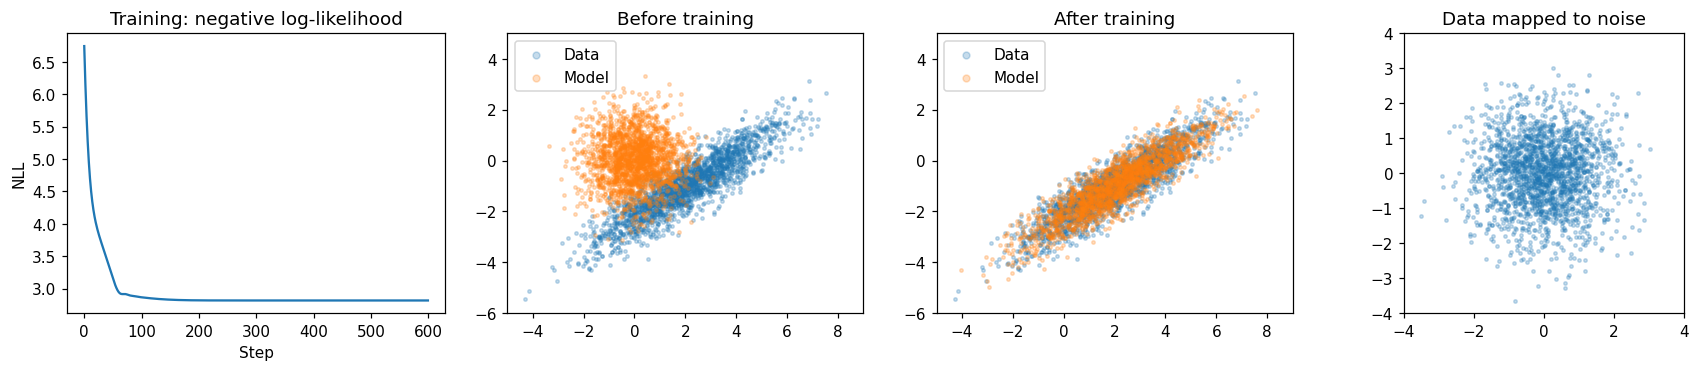

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].plot(linear_losses)
axes[0].set(title="Training: negative log-likelihood", xlabel="Step", ylabel="NLL")
for ax, samples, title in zip(
    axes[1:3], [linear_before, linear_after], ["Before training", "After training"]
):
    ax.scatter(*linear_data.numpy().T, s=5, alpha=.25, label="Data")
    ax.scatter(*samples.T, s=5, alpha=.25, label="Model")
    ax.set(title=title, xlim=(-5, 9), ylim=(-6, 5), aspect="equal")
    ax.legend(markerscale=2)
axes[3].scatter(*linear_encoded.T, s=5, alpha=.25)
axes[3].set(title="Data mapped to noise", xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
plt.tight_layout()
plt.show()

#### Real NVP

**RealNVP (Real-valued Non-Volume Preserving)**

[arxiv](https://arxiv.org/abs/1605.08803)

* строит сложное распределение через композицию простых преобразований
* сохраняет обратимость
* делает вычисление якобиана дешёвым


- **1. Coupling layer**

Пусть вход:
$$
x = (x_1, x_2)
$$

Coupling layer делает:

$$
y_1 = x_1
$$
$$
y_2 = x_2 \odot \exp(s(x_1)) + t(x_1)
$$

где:

* $s(\cdot)$ scale network
* $t(\cdot)$ translation network

- **2. Якобиан**

Матрица якоби получается *треугольной*:

$$
J =
\begin{pmatrix}
I & 0 \\

* & \text{diag}(\exp(s(x_1)))
  \end{pmatrix}
$$

Поэтому:

$$
\log |\det J| = \sum s(x_1)
$$

* детерминант считается за ( O(n) )

- **3. Обратное преобразование**

$$
x_1 = y_1
$$
$$
x_2 = (y_2 - t(y_1)) \odot \exp(-s(y_1))
$$

- **4. Полная модель**

$$
z = f(x) = f_K \circ \dots \circ f_1(x)
$$

между слоями:

* меняется маска
* перемешиваются координаты

<img src="assets/realnvp.png" width="500">

In [ ]:
import math
import numpy as np
import torch
from torch import nn

torch.manual_seed(42)

a = torch.rand(1000) * math.pi
moon1 = torch.stack([a.cos(), a.sin()], dim=1)
moon2 = torch.stack([1 - a.cos(), 0.5 - a.sin()], dim=1)
nvp_data = torch.cat([moon1, moon2]) + 0.07 * torch.randn(2000, 2)
nvp_data = (nvp_data - nvp_data.mean(0)) / nvp_data.std(0)

class Coupling(nn.Module):
    def __init__(self, flip=False):
        super().__init__()
        self.flip = flip
        self.net = nn.Sequential(
            nn.Linear(1, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 2)
        )

        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def transform(self, x, inverse=False):

        if self.flip:
            x = x.flip(dims=[1])
        fixed, changed = x[:, :1], x[:, 1:]
        raw_s, shift = self.net(fixed).chunk(2, dim=1)
        log_scale = 0.8 * torch.tanh(raw_s)  # ограничиваем масштаб для устойчивости
        if inverse:
            changed = (changed - shift) * torch.exp(-log_scale)
            log_det = -log_scale[:, 0]
        else:
            changed = changed * torch.exp(log_scale) + shift
            log_det = log_scale[:, 0]
        y = torch.cat([fixed, changed], dim=1)
        if self.flip:
            y = y.flip(dims=[1])
        return y, log_det

class RealNVP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([Coupling(flip=bool(k % 2)) for k in range(6)])

    def encode(self, x):
        log_det = x.new_zeros(x.shape[0])
        for layer in self.layers:
            x, layer_log_det = layer.transform(x)
            log_det = log_det + layer_log_det
        return x, log_det

    def log_prob(self, x):
        z, log_det = self.encode(x)
        log_pz = -0.5 * (z.square() + math.log(2 * math.pi)).sum(dim=1)
        return log_pz + log_det

    def decode(self, z):
        for layer in reversed(self.layers):
            z, _ = layer.transform(z, inverse=True)
        return z

nvp = RealNVP()
nvp_optimizer = torch.optim.Adam(nvp.parameters(), lr=0.001)
nvp_losses = []
for step in range(2000):
    batch = nvp_data[torch.randint(len(nvp_data), (256,))]
    loss = -nvp.log_prob(batch).mean()
    nvp_optimizer.zero_grad()
    loss.backward()
    nvp_optimizer.step()
    nvp_losses.append(loss.item())

nvp.eval()
with torch.no_grad():
    nvp_generated = nvp.decode(torch.randn(2000, 2)).numpy()
    nvp_latent, _ = nvp.encode(nvp_data)
    reconstruction_error = (nvp.decode(nvp_latent) - nvp_data).abs().max().item()
    nvp_latent = nvp_latent.numpy()
print(f"NLL, среднее первых/последних 100 шагов: "
      f"{np.mean(nvp_losses[:100]):.3f} → {np.mean(nvp_losses[-100:]):.3f}")
print(f"Максимальная ошибка decode(encode(x)): {reconstruction_error:.2e}")

NLL, среднее первых/последних 100 шагов: 2.631 → 1.595
Максимальная ошибка decode(encode(x)): 2.86e-06


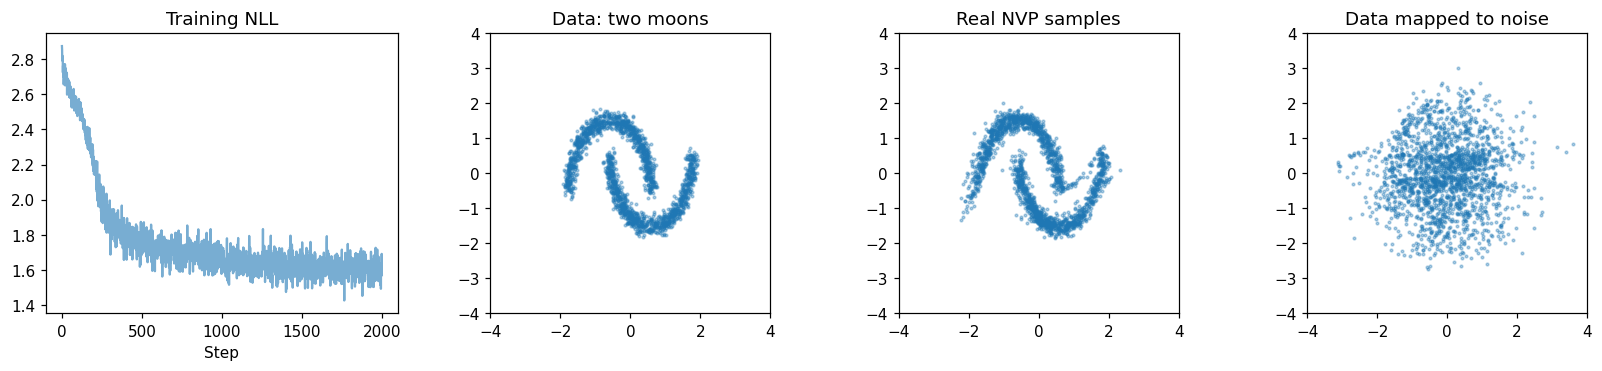

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
axes[0].plot(nvp_losses, alpha=.6)
axes[0].set(title="Training NLL", xlabel="Step")
for ax, points, title in zip(
    axes[1:], [nvp_data.numpy(), nvp_generated, nvp_latent],
    ["Data: two moons", "Real NVP samples", "Data mapped to noise"]
):
    ax.scatter(*points.T, s=3, alpha=.35)
    ax.set(title=title, xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
plt.tight_layout()
plt.show()

## 2. Continuous Normalizing Flow

### От последовательности слоёв к непрерывному движению

В NF каждый слой сразу преобразует точку. Попробуем вместо этого много раз чуть-чуть сдвигать её:
$$x_{t+\Delta t}=x_t+\Delta t\,v_\theta(x_t,t).$$
Сеть $v_\theta$ получает **текущую точку и время**, возвращает скорость той же размерности.

При уменьшении шага это численная аппроксимация ODE — обыкновенного дифференциального уравнения:
$$\frac{dx_t}{dt}=v_\theta(x_t,t),\qquad x_0\sim\mathcal N(0,I).$$

**CNF — модель, в которой такое непрерывное движение преобразует простое распределение в распределение данных.** Neural ODE — более общий способ задавать вычисление через ODE; CNF использует его для переноса распределения и учёта плотности. См. [Neural ODE](https://arxiv.org/abs/1806.07366).

**Теорема о непрерывной замене переменных** (instantaneous change of variables). Для достаточно гладкого поля изменение log-плотности вдоль траектории равно минус локальной скорости расширения объёма:
$$\frac{d}{dt}\log p_t(x_t)=-\operatorname{div}v_\theta(x_t,t).$$

Здесь divergence — сумма производных: насколько скорость по каждой координате растёт при движении по этой же координате. См. [Neural ODE, теорема 1](https://arxiv.org/abs/1806.07366).

### Как обучать CNF через likelihood и почему это дорого

Для картинки из датасета интегрируем ODE **назад**: получаем её начальный шум и одновременно накапливаем изменение log-плотности. Плотность шума известна; с поправкой на расширение получаем плотность картинки. Максимизируем её по параметрам сети.

На каждой итерации обучения нужны несколько вызовов сети внутри ODE-решателя, вычисление divergence и градиенты через всё вычисление. В высокой размерности даже trace может быть дорогим. В [FFJORD](https://arxiv.org/abs/1810.01367) его оценивают стохастически с помощью произведений Якобиана на вектор.

CNF снимает требование coupling-архитектуры, но сохраняет стоимость численного интегрирования.

**Следующий вопрос: можно ли обучить ту же сеть скоростей без решения ODE на каждом шаге обучения?**

## 3. Flow Matching: обучение CNF по известным скоростям

[Paper](https://arxiv.org/pdf/2210.02747)

**Flow Matching — способ обучения поля скоростей CNF через регрессию.** Заранее выбираем, как распределение должно меняться между шумом и данными, и учим сеть предсказывать скорости, которые обеспечивают этот перенос.

$$\boxed{\mathcal L(\theta)=\mathbb E\|v_\theta(x_t,t)-u_t(x_t)\|^2}$$

### Откуда взять правильную скорость?

Хотелось бы знать поле, переносящее всё распределение, но оно неизвестно. Зато легко задать движение **для отдельной пары** шум–данные: выбрать путь и вычислить его производную.

Обучаем сеть на состояниях и скоростях этих простых путей. Такой практический подход называют **Conditional Flow Matching**: условие — выбранная пара.

Обоснование эквивалентности условной и общей регрессии — [Flow Matching, теорема 2](https://arxiv.org/abs/2210.02747): их losses дают одинаковые градиенты.

### Rectified Flow: выбираем прямые пути

[Paper](https://arxiv.org/pdf/2209.03003)

1. Берём изображение $x_1$ из датасета.
2. Независимо генерируем шум $x_0\sim\mathcal N(0,I)$ той же формы.
3. Выбираем $t\sim U[0,1]$.
4. Смешиваем: $x_t=(1-t)x_0+t x_1$.
5. Правильная скорость **этой пары**: $u=x_1-x_0$.

$$\boxed{\mathcal L(\theta)=\mathbb E\|v_\theta(x_t,t)-(x_1-x_0)\|^2}$$

### Пример: перемещаем и растягиваем облако точек

In [ ]:
import numpy as np
import torch
from torch import nn

torch.manual_seed(12)


def rf_data(count):
    return torch.randn(count, 2) * torch.tensor([1.4, 0.4]) + torch.tensor([4., 2.])

rf_net = nn.Sequential(
    nn.Linear(3, 64), nn.Tanh(),
    nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 2)
)
rf_optimizer = torch.optim.Adam(rf_net.parameters(), lr=0.002)
rf_losses = []
for step in range(2000):
    x0 = torch.randn(256, 2)
    x1 = rf_data(256)
    t = torch.rand(256, 1)
    xt = (1 - t) * x0 + t * x1
    target = x1 - x0
    # Вход: две координаты текущей точки и время. Выход: две компоненты скорости.
    predicted = rf_net(torch.cat([xt, t], dim=1))
    loss = (predicted - target).square().mean()
    rf_optimizer.zero_grad()
    loss.backward()
    rf_optimizer.step()
    rf_losses.append(loss.item())

rf_net.eval()
@torch.no_grad()
def rf_path(initial, steps=80):
    x = initial.clone()
    path = [x.numpy().copy()]
    for k in range(steps):
        t = x.new_full((len(x), 1), k / steps)
        x = x + rf_net(torch.cat([x, t], dim=1)) / steps
        path.append(x.numpy().copy())
    return np.stack(path)

rf_initial = torch.randn(800, 2)
rf_target = rf_data(800).numpy()
rf_trajectory = rf_path(rf_initial)

rf_pair_start = torch.randn(8, 2).numpy()
rf_pair_end = rf_data(8).numpy()
print(f"Средний MSE первых/последних 100 шагов: "
      f"{np.mean(rf_losses[:100]):.3f} → {np.mean(rf_losses[-100:]):.3f}")

Средний MSE первых/последних 100 шагов: 3.042 → 1.459


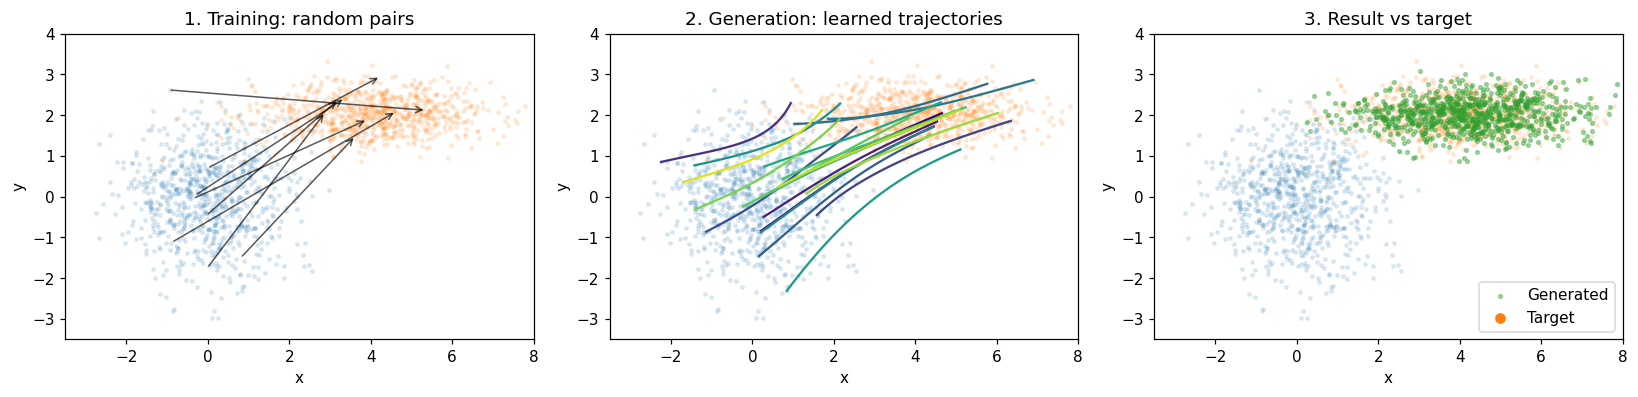

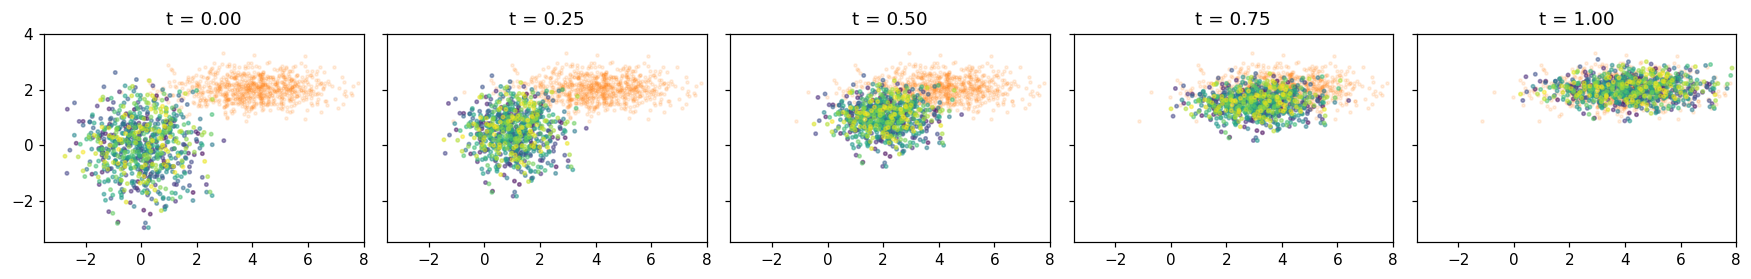

In [ ]:
import matplotlib.pyplot as plt

rf_colors = plt.cm.viridis(np.linspace(0, 1, len(rf_initial)))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax in axes:
    ax.scatter(*rf_initial.numpy().T, s=5, alpha=.12, color="tab:blue")
    ax.scatter(*rf_target.T, s=5, alpha=.12, color="tab:orange")
    ax.set(xlim=(-3.5, 8), ylim=(-3.5, 4), aspect="equal", xlabel="x", ylabel="y")
axes[0].set_title("1. Training: random pairs")
for a, b in zip(rf_pair_start, rf_pair_end):
    axes[0].annotate("", xy=b, xytext=a,
                     arrowprops=dict(arrowstyle="->", color="black", alpha=.65))
axes[1].set_title("2. Generation: learned trajectories")
for j in range(0, len(rf_initial), 40):
    axes[1].plot(rf_trajectory[:, j, 0], rf_trajectory[:, j, 1], color=rf_colors[j])
axes[2].set_title("3. Result vs target")
axes[2].scatter(*rf_trajectory[-1].T, s=6, alpha=.4, color="tab:green", label="Generated")
axes[2].scatter([], [], color="tab:orange", label="Target")
axes[2].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharex=True, sharey=True)
for ax, index in zip(axes, [0, 20, 40, 60, 80]):
    ax.scatter(*rf_target.T, s=4, alpha=.12, color="tab:orange")
    ax.scatter(*rf_trajectory[index].T, s=5, alpha=.5, c=rf_colors)
    ax.set(title=f"t = {index / 80:.2f}", xlim=(-3.5, 8), ylim=(-3.5, 4), aspect="equal")
plt.tight_layout(); plt.show()

### Семплирование: сколько шагов нужно?

Используем Euler: $x\leftarrow x+v_\theta(x,t)/N$, где $N$ — число шагов. После каждого шага заново вычисляем скорость в новой точке.

Сравним генерацию при одинаковом начальном шуме.

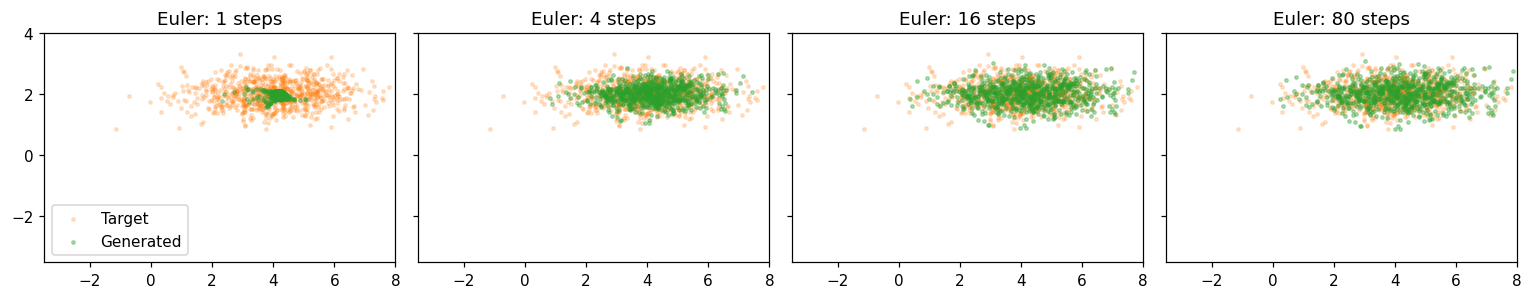

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True, sharey=True)
for ax, steps in zip(axes, [1, 4, 16, 80]):
    result = rf_path(rf_initial, steps)[-1]
    ax.scatter(*rf_target.T, s=5, alpha=.2, color="tab:orange", label="Target")
    ax.scatter(*result.T, s=5, alpha=.35, color="tab:green", label="Generated")
    ax.set(title=f"Euler: {steps} steps", xlim=(-3.5, 8), ylim=(-3.5, 4), aspect="equal")
axes[0].legend()
plt.tight_layout(); plt.show()

### Reflow: научим модель на более разумных парах 

[Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow (2022)](https://arxiv.org/abs/2209.03003). 

В статье введена процедура **reflow** — повторное обучение RF на парах, полученных предыдущим потоком.

Начальные независимые пары создают много конфликтующих направлений.

1. Берём шум $z_0$.
2. Генерируем $z_1$ teacher-моделью с достаточно точным ODE-решением.
3. Фиксируем пару $(z_0,z_1)$ и учим новое поле на её прямой интерполяции с target $z_1-z_0$.
4. Проверяем качество при меньшем числе шагов. При необходимости повторяем.

**Reflow не равно distillation.** Reflow переобучает поле на новых парах во всём времени; distillation может напрямую учить student воспроизводить конечный результат teacher за один или несколько шагов. Teacher может передать и свои ошибки. Построение новых пар тоже требует вычислений.

## Что почитать дополнительно

- [A Visual Dive into Conditional Flow Matching](https://dl.heeere.com/conditional-flow-matching/blog/conditional-flow-matching/) – хороший вводный пост; полезно для понимания, как работает CFM.
- [Rectified Flow: Straight is Fast](https://rectifiedflow.github.io/blog/2024/intro/) – Авторский визуальный вводный пост.

- **[Diffusion Meets Flow Matching: Two Sides of the Same Coin](https://diffusionflow.github.io/) – связь diffusion и flow matching.**
- **[flow_matching](https://github.com/facebookresearch/flow_matching) – python библиотека flow matching алгоритмов.**
- **[Scaling Rectified Flow Transformers](https://arxiv.org/abs/2403.03206) – Переход к масштабной генерации изображений и мультимодальной архитектуре.**